<a href="https://colab.research.google.com/github/keyvanmahmoudi/Data_Science_Course/blob/main/solutions/Session11_final_project_solutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# پاسخ تمرین‌های جلسهٔ ۱۱: پروژهٔ پایانی، تحلیل سفرهای تاکسی نیویورک

این نوت‌بوک پاسخ پیشنهادی تمرین‌های انتهای [نوت‌بوک جلسه](../sessions/Session11_final_project.ipynb) است. قبل از دیدن پاسخ‌ها، خودتان تمرین‌ها را حل کنید؛ معمولاً بیش از یک راه‌حل درست وجود دارد.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### آماده‌سازی

کتابخانه‌ها و داده‌هایی که پاسخ‌ها به آن‌ها نیاز دارند:

</div>

In [1]:
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

DATA_URL = "https://raw.githubusercontent.com/keyvanmahmoudi/Data_Science_Course/main/data/"
raw = pd.read_csv(DATA_URL + "taxis.csv", parse_dates=["pickup", "dropoff"])
df = raw.copy()
df["duration_min"] = (df["dropoff"] - df["pickup"]).dt.total_seconds() / 60
df = df[(df["duration_min"] > 0) & (df["distance"] > 0) & (df["pickup"] >= "2019-03-01")].copy()
df["speed_mph"] = df["distance"] / (df["duration_min"] / 60)
df = df[df["speed_mph"] <= 60].copy()
df["tip_pct"] = df["tip"] / df["fare"] * 100

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۱

سفرهایی را که مبدأ یا مقصدشان فرودگاه است (نام منطقه شامل `Airport`) جدا کنید. تعداد، میانهٔ مسافت و میانهٔ کرایهٔ آن‌ها را با بقیهٔ سفرها مقایسه کنید.

</div>

In [2]:
is_airport = (df["pickup_zone"].str.contains("Airport", na=False)
              | df["dropoff_zone"].str.contains("Airport", na=False))
df.groupby(is_airport.map({True: "airport", False: "other"})).agg(
    trips=("fare", "count"),
    median_miles=("distance", "median"),
    median_fare=("fare", "median"),
).round(2)

,trips,median_miles,median_fare
airport,401,10.88,36.0
other,5969,1.56,9.0


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۲

میانهٔ سرعت سفرها (مایل بر ساعت) را برای هر ساعت از روز حساب و رسم کنید. ترافیک در کدام ساعت سنگین‌تر است؟

</div>

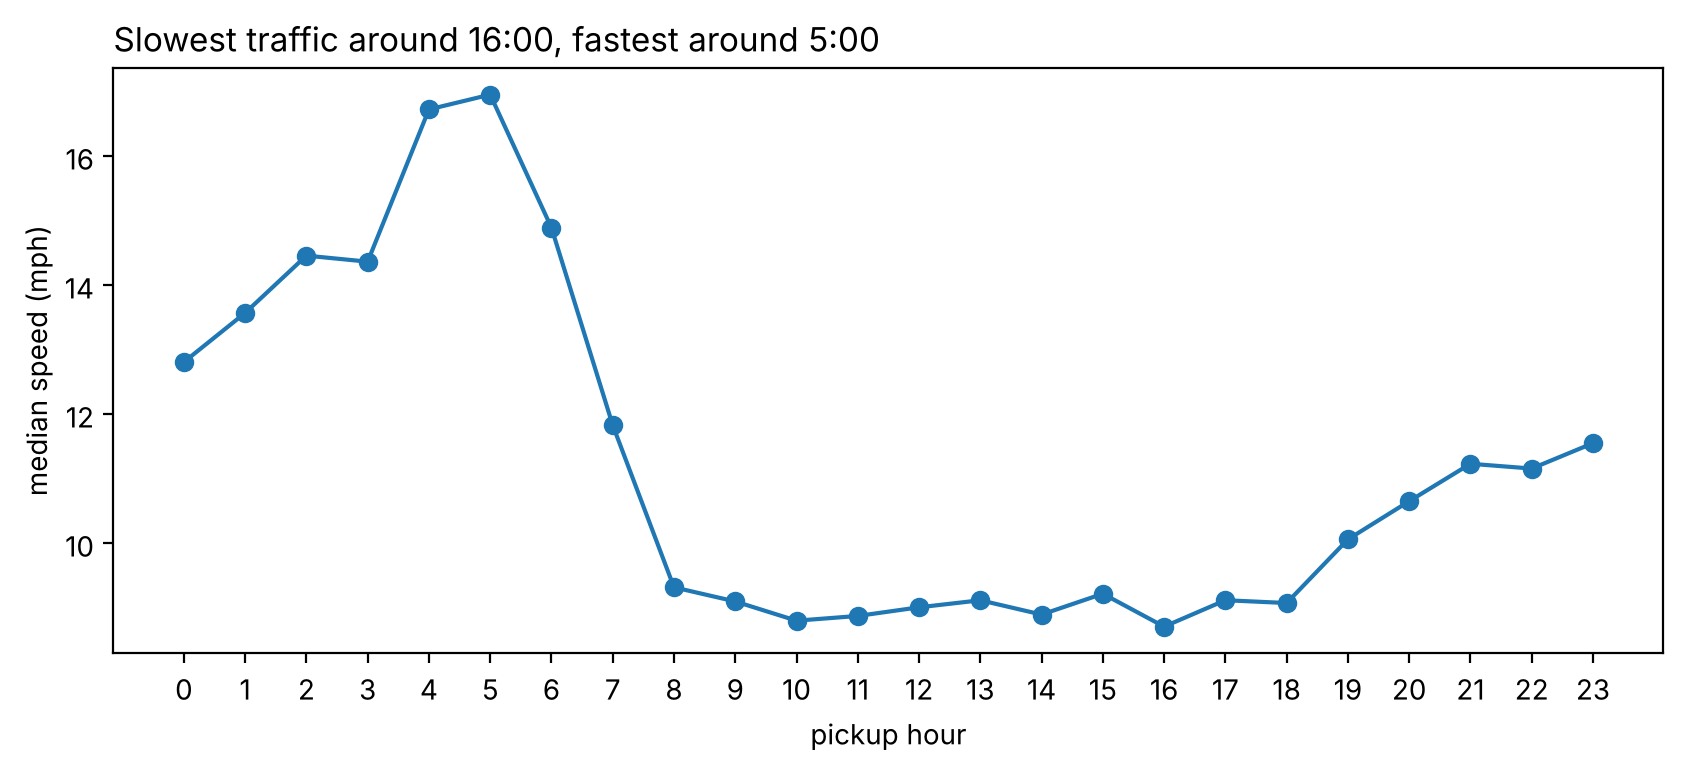

In [3]:
speed = df.groupby(df["pickup"].dt.hour)["speed_mph"].median()
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(speed.index, speed.values, marker="o")
ax.set_xticks(range(24))
ax.set_xlabel("pickup hour")
ax.set_ylabel("median speed (mph)")
ax.set_title(f"Slowest traffic around {speed.idxmin()}:00, fastest around {speed.idxmax()}:00", loc="left")
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۳

با SQL و تابع پنجره‌ای `RANK`، سه منطقهٔ پرتردد (بر اساس تعداد سفر) را در هر محله (`pickup_borough`) پیدا کنید.

</div>

In [4]:
conn = sqlite3.connect(":memory:")
df[["pickup_borough", "pickup_zone"]].to_sql("trips", conn, index=False)
pd.read_sql_query("""
WITH zone_counts AS (
    SELECT pickup_borough AS borough, pickup_zone AS zone, COUNT(*) AS trips
    FROM trips
    WHERE pickup_borough IS NOT NULL AND pickup_zone IS NOT NULL
    GROUP BY borough, zone
),
ranked AS (
    SELECT *, RANK() OVER (PARTITION BY borough ORDER BY trips DESC) AS rnk
    FROM zone_counts
)
SELECT borough, zone, trips FROM ranked WHERE rnk <= 3 ORDER BY borough, trips DESC
""", conn)

,borough,zone,trips
0,Bronx,East Concourse/Concourse Village,9
1,Bronx,Mott Haven/Port Morris,8
2,Bronx,Parkchester,7
3,Brooklyn,Fort Greene,38
4,Brooklyn,Downtown Brooklyn/MetroTech,36
5,Brooklyn,Brooklyn Heights,34
6,Manhattan,Midtown Center,229
7,Manhattan,Upper East Side South,211
8,Manhattan,Penn Station/Madison Sq West,210
9,Queens,LaGuardia Airport,146


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۴

در سفرهای کارتی، آیا درصد انعام با مسافت سفر رابطه دارد؟ ضریب همبستگی اسپیرمن را حساب کنید و میانهٔ درصد انعام را برای چهار دستهٔ مسافت (با `pd.qcut`) گزارش کنید.

</div>

In [5]:
card = df[df["payment"] == "credit card"].copy()
rho, p = stats.spearmanr(card["distance"], card["tip_pct"])
print(f"Spearman rho = {rho:.3f} (p = {p:.1e})")
card["distance_band"] = pd.qcut(card["distance"], 4, labels=["shortest", "short", "long", "longest"])
card.groupby("distance_band", observed=True)["tip_pct"].agg(["count", "median"]).round(1)

Spearman rho = -0.446 (p = 1.9e-221)


,count,median
distance_band,,
shortest,1145,31.7
short,1134,27.8
long,1150,25.4
longest,1120,22.2


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

همبستگی منفی و در حد متوسط است: در سفرهای طولانی‌تر، انعام **نسبت به کرایه** کمی کمتر است، هرچند مبلغ انعام بیشتر است. همان الگویی که در دادهٔ رستوران هم دیدیم.

</div>